# Série 9

## Description
Un arbre binaire peut être utilisé pour stocker une liste ordonnée d'éléments de manière à ce que la recherche et les insertions soient efficaces. Un arbre binaire utilisé de cette manière s'appelle un **arbre de tri binaire** (ou BST).

Un arbre de tri binaire est un arbre binaire ayant la propriété suivante : pour chaque nœud de l'arbre, l'élément de ce nœud est supérieur à chaque élément du sous-arbre gauche de ce nœud, et il est inférieur ou égal à tous les éléments du sous-arbre droit de ce nœud. L'exemple ci-dessous montre un arbre de tri binaire contenant des éléments de type `String`, mais il en va de même pour les entiers, ou d'autres types comparables.


## Evaluation
Le but de l'évaluation est de montrer expérimentalement, au moyen d'une implémentation et de quelques évaluations simples, l'affirmation $H_0$ suivante :
>Si un **arbre de tri binaire** est créé **aléatoirement suivant une loi uniforme**, il y a une forte probabilité que l'arbre soit **approximativement équilibré** (*i.e.*, l'écart type de la distribution de la profondeur des feuilles est faible).

### Exercice 1
Testez la structure de données fournie en implémentant la méthode `to_sorted_list` qui retourne une liste avec les éléments ordonnés contenu dans l'arbre, du plus petit au plus grand.

In [1]:
# Un objet de type TreeNode représente un nœud.
class TreeNode():
    def __init__ (self, item):
        self.item = item
        self.left = None    # Objet TreeNode qui pointe vers le sous-arbre gauche.
        self.right = None   # Objet TreeNode qui pointe vers le sous-arbre droit.

class Tree:
    def __init__(self):
        self.root = None

    def insert(self, new_item):
        if self.root == None:
            self.root = TreeNode(new_item)
            return
        # Descend dans l'arbre pour trouver une place pour new_item.
        # Nous commençons par la racine
        runner = self.root
        while(True):
            # Puisque le nouvel élément est inférieur à l'élément runner,
            # il appartient au sous-arbre gauche du coureur.
            # S'il y a un espace libre à runner.left, on ajoute un nœud.
            # Sinon, on avance runner d'un niveau vers la gauche.
            if new_item < runner.item:
                if runner.left == None:
                    runner.left = TreeNode(new_item)
                    # Un nouvel élément a été ajouté à l'arbre
                    return
                else:
                    runner = runner.left
            # Puisque le nouvel élément est supérieur ou égal à l'élément runner,
            # il appartient au sous-arbre droit de runner.
            # S'il y a un espace libre à runner.right, on ajoute un nouveau nœud.
            # Sinon, on avance runner d'un niveau vers la droite.
            else:
                if runner.right == None:
                    runner.right = TreeNode(new_item)
                    # Un nouvel élément a été ajouté à l'arbre.
                    return
                else:
                    runner = runner.right


    def contains(self, item):
        # Retourne True si item est un des items de l'arbre de tri binaire vers lequel le nœud pointe.
        # Retourne False si ce n'est pas le cas
        def contains_internal(node, item):
            # L'arbre est vide, il ne contient donc certainement pas d'élément.
            if node == None:
                return False
            # l'élément a été trouvé dans le nœud racine.
            elif item == node.item:
                return True
            # Si l'élément apparaît, il doit se trouver dans le sous-arbre de gauche
            # On renvoie le résultat de la recherche dans le sous-arbre de gauche
            elif item < node.item:
                return contains_internal(node.left, item)
            # Si l'élément apparaît, il doit se trouver dans le sous-arbre de droite
            # On renvoie le résultat de la recherche dans le sous-arbre de droite
            else:
                return contains_internal(node.right, item)

        return contains_internal(self.root, item)

    # liste ordonnée croissante des élément du BST
    def to_sorted_list(self):
        sorted_list = []

        def sorted_func(node):
            if node is None:
              return sorted_list
            else:
              sorted_func(node.left)    #on utilise la récursivité pour parcourir l'arbre avec ces 3 lignes
              sorted_list.append(node.item)
              sorted_func(node.right)

        sorted_func(self.root)
        return sorted_list

        raise NotImplementedError


In [2]:
t = Tree()
t.insert("d")
t.insert("b")
t.insert("f")
t.insert("c")
t.insert("a")
t.insert("e")
t.insert("g")
sorted_list = t.to_sorted_list()
assert ["a", "b", "c", "d", "e", "f", "g"] == sorted_list
assert t.contains("a")
assert not t.contains("z")

### Exercice 2
Créez un arbre de tri binaire aléatoire suivant $U[\![0;1000]\!]$ avec $2^{15}$ (32'768) nœuds. Vous pouvez remplir l'arbre en utilisant la méthode `insert` (voir le code source). Affichez les nombres du plus petits aux plus grands.

In [3]:
import random

AA = Tree()
for i in range(2**15):
  AA.insert(random.randint(0,1000))

to_sorted_list = AA.to_sorted_list()
#print(to_sorted_list)


### Exercice 3
Calculez et affichez la profondeur moyenne de toutes les feuilles de l'arbre créé dans l'exercice 2.

Pour vous aider vous pourriez créer un petit fichier texte appelé `depths.txt`, avec la profondeur de chaque feuille, une valeur par ligne. Mais vous pouvez utiliser une variable pour stocker l'information. Une liste ferait l'affaire.

Pour ce faire, vous aurez besoin de deux fonctions récursives : une pour compter les feuilles et une pour trouver la somme des profondeurs de toutes les feuilles. Cette dernière routine doivent accepter un paramètre de type entier (depth), qui indique à quelle profondeur de l'arbre vous êtes allés. Lorsque vous appelez cette routine de manière récursive, la valeur de la profondeur augmente de 1. Vous êtes libre de définir des paramètres additionels, mais la récusivité est exigée pour cet exercice.

In [4]:
# Fonction qui compte le nombre total de feuilles de manière récursive.
def count_leaves(root):
    if root is None:
      return 0

    elif root.left is None and root.right is None:
      return 1

    else:
      return count_leaves(root.left) + count_leaves(root.right)


# Fonction qui calcule la somme des profondeurs de chaque feuille de l'arbre de manière récursive.
def sum_depth(root, depth, file):
    if root is None:
      return 0
    elif root.left is None and root.right is None:
      file.write(str(depth) + "\n")
      return depth
    else:
      return sum_depth(root.left, depth+1, file) + sum_depth(root.right, depth+1, file)

In [5]:
random_tree = Tree()
for i in range(2**15):
  random_tree.insert(random.randint(0, 1000))

In [6]:
print("Number of leaves:")
counter = count_leaves(random_tree.root)
print(counter)
print("Sum of depth of all leaves")

with open("depths.txt", 'a+') as file:
    s = sum_depth(random_tree.root, 1, file)
print(s)
print("Average depth:")
print(s/counter)

Number of leaves:
1001
Sum of depth of all leaves
45196
Average depth:
45.15084915084915


#### Exercice 3.1 (<font color='#db60cf'>Bonus</font>)
Reportez dans un graphique la distribution des profondeurs des feuilles (il y a `counter` feuilles à afficher sur un histogramme). Vous pourrez vous aider en utilisant [Matplotlib](https://matplotlib.org/), un outil de visualisation pour Python. Matplotlib est déjà inclu dans la plupart des plateforms en ligne de Jupyter Notebook (notamment Colab).

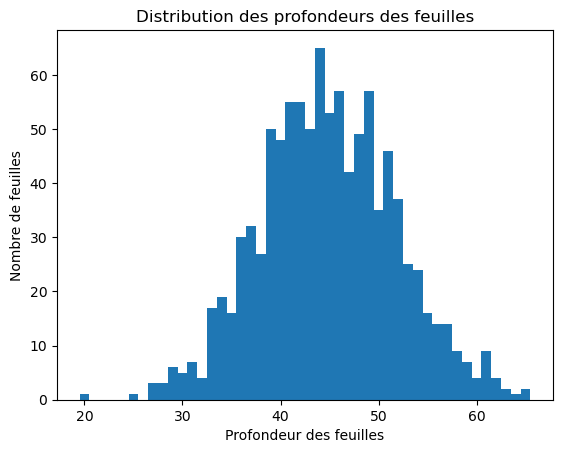

In [7]:
import matplotlib.pyplot as plt

#On remplit une liste petit à petit avec la profondeur
#des différentes feuilles rencontrées
def get_leaf_depths(node, depth, depths):
    # si le noeud n'existe pas on n'ajoute rien
    if node is None:
        return

    # si on a pas de suite à gauche ni droite
    #==> c'est une feuille on stocke la profondeur
    if node.left is None and node.right is None:
        depths.append(depth)
        return

    # sinon on descend dans les 2 sous-arbres
    get_leaf_depths(node.left, depth + 1, depths)
    get_leaf_depths(node.right, depth + 1, depths)

depths = []
get_leaf_depths(AA.root, 0, depths)


plt.hist(depths, bins=range(min(depths), max(depths) + 2), align='left')
plt.xlabel("Profondeur des feuilles")
plt.ylabel("Nombre de feuilles")
plt.title("Distribution des profondeurs des feuilles")
plt.show()

Ce résultat semble-t-il dans le sens de l'hypothèse $H_0$ formulée plus tôt ? Quel serait l'intérêt qu'une telle hypothèse fût vraie ? Quelle allure aurait l'histogramme si le BST était parfaitement équilibré ?

On remarque qu'on a en insérant des valeurs aléatoires une répartition normale entre le nombre de feuille en fonction de la profondeur donc celà va dans le sens de notre hypothèse H0.
l'intéret est que plus un arbre est équillibré plus la recherche d'un nombre va être simple : si on est plus grand que le noeud on coupe la moitié gauche sinon la moitié droite et ainsi de suite, l'arbre étant équillibré assure que le chemin à gauche sera autant court que celui à droite.
Si on avait un arbre déséquillibré complètement :
1
 \
  2
   \
    3
     \
      4
       \
        5
         ...
Ici on a une profondeur de 5 donc pour retomber sur 5 il nous faut 5 étapes.
(si on pousse à l'extreme un tel arbre pour ... on va jusqu'à 1000 il nous faut 1000 opérations) c'est super long.

Si on notre BST était parfaitement équillibré en développant l'arbre on constate que toutes les feuilles sont à la même profondeur donc on aurait une grande barre.



Faites varier la limite supérieure en paramètre de votre générateur uniforme d'entiers parmi `np.arange(50, 500, 10)` en prenant soin de conserver à chaque fois l'écart type et la moyenne de la distribution. Que remarquez-vous ? Comment l'expliqueriez-vous ?

100%|██████████| 45/45 [00:17<00:00,  2.54it/s]


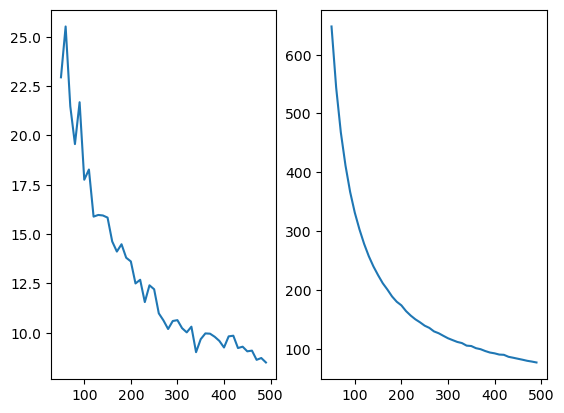

In [8]:
import numpy as np
import statistics
import tqdm
import random

means, stddevs = [], []

for largest_possible_number in tqdm.tqdm(np.arange(50, 500, 10)):

    A = Tree()

    # remplir avec 2^15 valeurs aléatoires entre 0 et largest_possible_number
    for _ in range(2**15):
        A.insert(random.randint(0, largest_possible_number))
    # récupérer les profondeurs des feuilles
    depths = []
    get_leaf_depths(A.root, 0, depths)

    # stocker la moyenne et l'écart-type
    means.append(statistics.mean(depths))
    stddevs.append(statistics.stdev(depths))


# plot de l'écart-type et de la moyenne en fonction du paramètre de loi uniforme lors de la création du BST
plt.subplot(1, 2, 1)
plt.plot(np.arange(50, 500, 10), stddevs)
plt.subplot(1, 2, 2)
plt.plot(np.arange(50, 500, 10), means)

Plus la borne sup est élévée, moins on a chance de doublons et donc plus l'arbre se comporte bien : il est régulier, il est légèrement plus équillibréé
l’écart-type des profondeurs diminue légèrement lorsque la borne augmente